# Coeliac antigen specificity with AlphaFold3

In this notebook, we assess how well AlphaFold3 can predict the decoy non-binders from the true binders in the Coeliac dataset.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pingouin as pg
import seaborn as sns
from sklearn.metrics import roc_auc_score

In [2]:
NUM_SAMPLES = 25
SAMPLE_SIZE = 500
SEED = 123
SIGNIFICANCE_LEVEL = 0.05

In [3]:
sequences = pd.read_csv('../data/interim/sequences_coeliac_with_negatives.csv', index_col='id')
sequences['type'] = sequences['label'].map(lambda label: 'Binder' if label else 'Non-Binder')

In [4]:
confidence_scores = pd.read_csv('../data/interim/confidence_scores_af3_af3_tcrmodel2_coeliac.csv')

In [5]:
confidence_scores = confidence_scores.merge(sequences, how='inner', left_on='name', right_index=True)

ROC-AUC: 0.6583217598252563


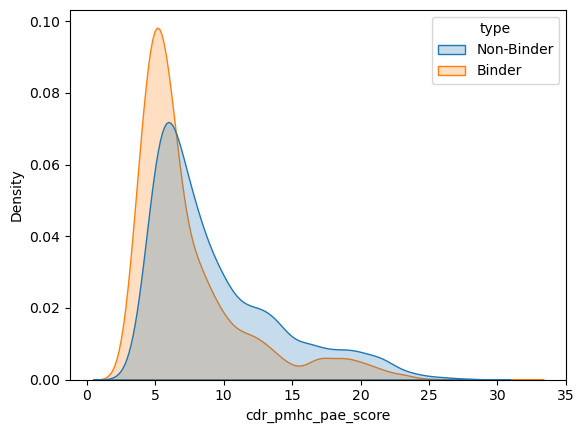

In [6]:
sns.kdeplot(confidence_scores.sort_values('label', ascending=True), x='cdr_pmhc_pae_score', hue='type', fill=True)

print('ROC-AUC:', 1 - roc_auc_score(confidence_scores['label'], confidence_scores['cdr_pmhc_pae_score']))

plt.show()

In [7]:
rng = np.random.default_rng(SEED)

bootstrap_scores = {
    'sample_num': [],
    'roc_auc_score': [],
}

for sample_num in range(1, NUM_SAMPLES + 1):
    bootstrap_scores['sample_num'].append(sample_num)

    sample = confidence_scores.sample(SAMPLE_SIZE, random_state=rng)
    bootstrap_scores['roc_auc_score'].append(1 - roc_auc_score(sample['label'], sample['cdr_pmhc_pae_score']))

bootstrap_scores = pd.DataFrame(bootstrap_scores)

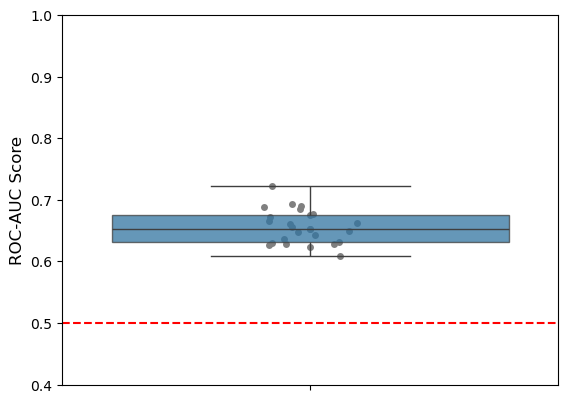

In [8]:
fig, ax = plt.subplots(1, 1)

sns.stripplot(bootstrap_scores, y='roc_auc_score', color='grey', ax=ax, zorder=1)
sns.boxplot(bootstrap_scores, y='roc_auc_score', ax=ax, color='tab:blue', boxprops={'alpha': 0.75}, zorder=2)

ax.axhline(0.5, color='red', linestyle='dashed')

ax.set_ylim([0.4, 1.0])

ax.set_ylabel('ROC-AUC Score', fontsize=12)

plt.show()

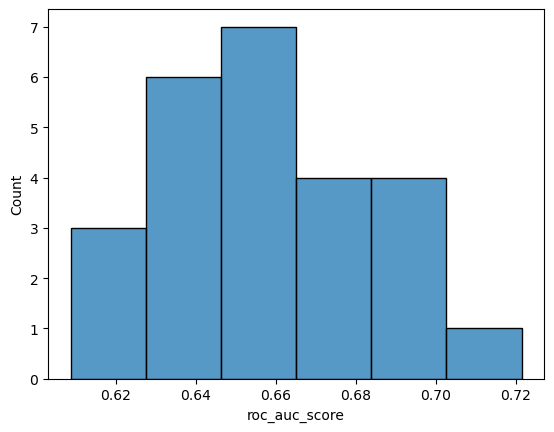

In [9]:
sns.histplot(bootstrap_scores, x='roc_auc_score')
plt.show()

In [10]:
results = pg.ttest(bootstrap_scores['roc_auc_score'], 0.5, alternative='greater', paired=False)
results['significant'] = results['p-val'] < SIGNIFICANCE_LEVEL

results

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power,significant
T-test,28.82267,24,greater,1.960980e-20,"[0.65, inf]",5.764534,1.738e+17,1.0,True


In [11]:
tcr_antigen_id = confidence_scores.groupby(['va_gene', 'cdr3a', 'ja_gene', 'vb_gene', 'cdr3b', 'jb_gene']).apply(
    lambda tcr_group: tcr_group.sort_values('cdr_pmhc_pae_score', ascending=True).iloc[0]['label'], include_groups=False
)

accuracy = 100 * tcr_antigen_id.sum() / len(tcr_antigen_id)

print(f'TCR-antigen ID Accuracy: {accuracy: .2f}%')

TCR-antigen ID Accuracy:  76.08%
